In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout, Rescaling, RandomFlip, RandomRotation, Input, Rescaling
import kagglehub
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [5]:
#Downloading the flower from Kaggle
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
PATH_DATASET = os.path.join(path, "flowers")

SIZE_IMAGE = (128, 128) #Size of each image
SIZE_LOT = 32 #Batch size

#Training data
dataset_training = tf.keras.utils.image_dataset_from_directory(
    PATH_DATASET,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=SIZE_IMAGE,
    batch_size=SIZE_LOT
)

#Validation data
dataset_validation = tf.keras.utils.image_dataset_from_directory(
    PATH_DATASET,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=SIZE_IMAGE,
    batch_size=SIZE_LOT
)

flowers_name = dataset_training.class_names
nb_class = len(flowers_name)
print(f"Flowers to recognize : {flowers_name}")

#Data augmentation : generate random variations of the images during the training (Flip, Rotation, Zoom)
data_augmentation = Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

100%|██████████| 225M/225M [01:41<00:00, 2.31MB/s] 

Extracting files...


Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Flowers to recognize : ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [6]:
from tensorflow.keras.layers import Input, Rescaling
from tensorflow.keras.applications import MobileNet

#Transfer Learning : load MobileNet pre-trained on ImageNet
conv_base = MobileNet(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
conv_base.trainable = False

modele = Sequential()
modele.add(Input(shape=(128, 128, 3)))

#Generate image with random modification, (randomflip, rotation, zoom)
modele.add(data_augmentation)

#Normalization :  brings pixel values from [0,255] to [0,1]
modele.add(Rescaling(1./255))

#Adding the MobileNet database
modele.add(conv_base)

#Flatten : converts 2D feature maps to a 1D vector.
modele.add(Flatten())

#Dense Layer : learn to combine the MobileNet features for our flower recognition problem
#ReLU Activation --> max(0,x) : remove the negative value
modele.add(Dense(128, activation='relu'))

#Dropout at 0.5, randomly turn off half of the neurons at each batch during the training
#Prevent neurons from depending too much on each other, --> reduce the overfitting
modele.add(Dropout(0.5))

#Softmax : give a probability distribution to each class, sum() = 1
modele.add(Dense(nb_class, activation='softmax'))

modele.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step


In [ ]:
modele.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
AUTOTUNE = tf.data.AUTOTUNE
dataset_training = dataset_training.cache().prefetch(buffer_size=AUTOTUNE)
dataset_validation = dataset_validation.cache().prefetch(buffer_size=AUTOTUNE)
historique = modele.fit(
    dataset_training,
    validation_data=dataset_validation,
    epochs=10,
)


Epoch 1/10


c:\Users\THEO\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 451ms/step - accuracy: 0.6844 - loss: 1.0800 - val_accuracy: 0.8239 - val_loss: 0.5272
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 40s 368ms/step - accuracy: 0.7490 - loss: 0.6847 - val_accuracy: 0.8331 - val_loss: 0.5368
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 39s 366ms/step - accuracy: 0.7820 - loss: 0.6114 - val_accuracy: 0.8482 - val_loss: 0.4193
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 42s 386ms/step - accuracy: 0.7962 - loss: 0.5616 - val_accuracy: 0.8308 - val_loss: 0.4842
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 47s 435ms/step - accuracy: 0.8159 - loss: 0.5016 - val_accuracy: 0.8540 - val_loss: 0.4223
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 48s 442ms/step - accuracy: 0.8237 - loss: 0.4731 - val_accuracy: 0.8413 - val_loss: 0.4752
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 42s 387ms/step - accuracy: 0.8382 - loss: 0.4530 - val_accuracy: 0.8482 - val_loss: 0.4452
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 44s 406ms/step - accuracy: 0.8277 - loss: 0.4434 - val

In [ ]:
#Fine-Tunning
conv_base.trainable = True
for layer in conv_base.layers[:-20]:
    layer.trainable = False

modele.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
AUTOTUNE = tf.data.AUTOTUNE
dataset_training = dataset_training.cache().prefetch(buffer_size=AUTOTUNE)
dataset_validation = dataset_validation.cache().prefetch(buffer_size=AUTOTUNE)
historique = modele.fit(
    dataset_training,
    validation_data=dataset_validation,
    epochs=10,
)


Epoch 1/10


c:\Users\THEO\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


108/108 ━━━━━━━━━━━━━━━━━━━━ 69s 564ms/step - accuracy: 0.8185 - loss: 0.5212 - val_accuracy: 0.8552 - val_loss: 0.4865
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 61s 563ms/step - accuracy: 0.8327 - loss: 0.4472 - val_accuracy: 0.8633 - val_loss: 0.4813
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 55s 507ms/step - accuracy: 0.8413 - loss: 0.4332 - val_accuracy: 0.8667 - val_loss: 0.4663
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 57s 530ms/step - accuracy: 0.8526 - loss: 0.4188 - val_accuracy: 0.8702 - val_loss: 0.4526
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 51s 477ms/step - accuracy: 0.8518 - loss: 0.4024 - val_accuracy: 0.8749 - val_loss: 0.4546
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 46s 425ms/step - accuracy: 0.8616 - loss: 0.3593 - val_accuracy: 0.8714 - val_loss: 0.4555
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 45s 417ms/step - accuracy: 0.8709 - loss: 0.3649 - val_accuracy: 0.8749 - val_loss: 0.4585
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 45s 417ms/step - accuracy: 0.8729 - loss: 0.3386 - val

In [21]:
# Creation of the folder 'models' if it does not exist, and save the model in it
os.makedirs('models', exist_ok=True)
save_path = os.path.join('models', 'my_flower_model.keras')
modele.save(save_path)

File : daisy.jpg            | DAISY      | Accuracy : 100.00 %


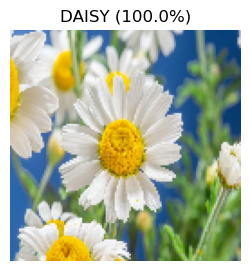

File : daisy1.jpg           | DAISY      | Accuracy : 100.00 %


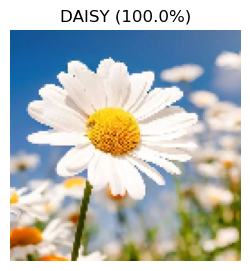

File : daisy2.jpg           | DAISY      | Accuracy : 100.00 %


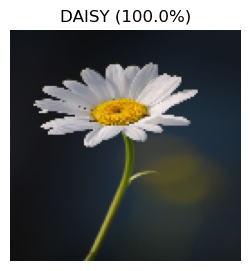

File : daisy3.jpg           | DAISY      | Accuracy :  99.97 %


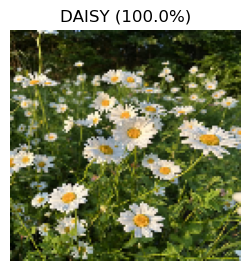

File : daisy4.jpg           | DAISY      | Accuracy : 100.00 %


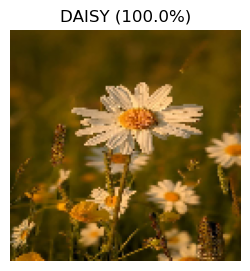

File : dandelions.jpg       | DANDELION  | Accuracy : 100.00 %


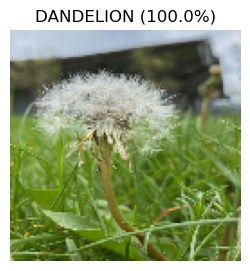

File : dandelions1.jpeg     | DANDELION  | Accuracy : 100.00 %


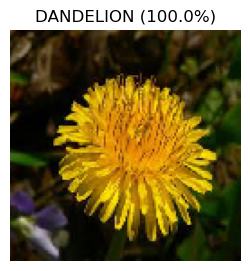

File : dandelions2.jpeg     | DANDELION  | Accuracy : 100.00 %


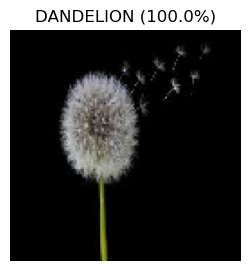

File : dandelions3.jpeg     | DANDELION  | Accuracy :  97.51 %


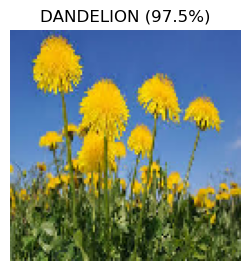

File : dandelions4.jpg      | DANDELION  | Accuracy :  99.99 %


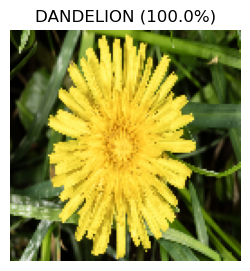

File : rose.jpeg            | ROSE       | Accuracy :  97.32 %


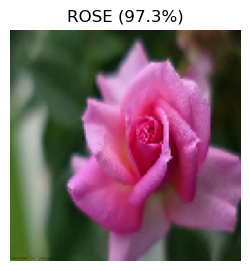

File : rose1.jpg            | ROSE       | Accuracy : 100.00 %


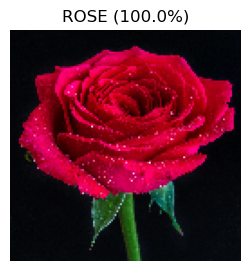

File : rose2.jpg            | ROSE       | Accuracy :  62.38 %


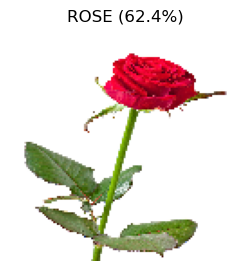

File : rose3.jpg            | ROSE       | Accuracy :  83.23 %


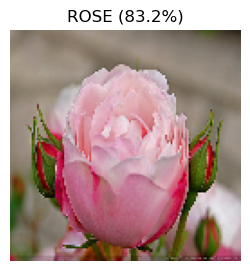

File : rose4.jpg            | TULIP      | Accuracy :  87.38 %


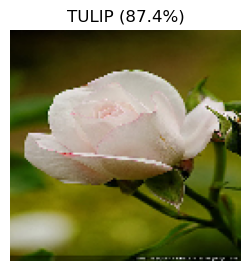

File : sunflower.jpg        | SUNFLOWER  | Accuracy : 100.00 %


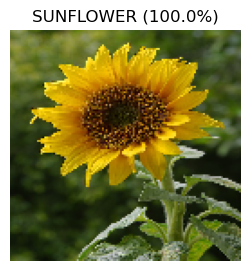

File : sunflower1.jpg       | SUNFLOWER  | Accuracy : 100.00 %


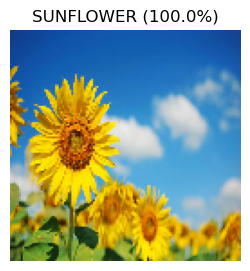

File : sunflower2.jpg       | SUNFLOWER  | Accuracy : 100.00 %


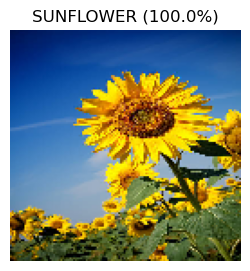

File : sunflower3.jpg       | SUNFLOWER  | Accuracy : 100.00 %


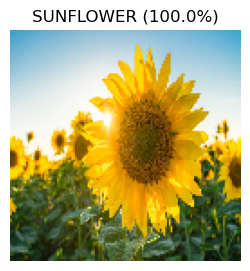

File : sunflower4.jpg       | SUNFLOWER  | Accuracy : 100.00 %


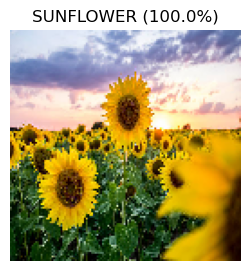

File : tulip.jpg            | TULIP      | Accuracy :  68.08 %


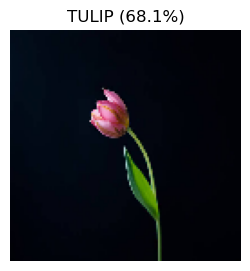

File : tulip1.jpg           | TULIP      | Accuracy :  99.91 %


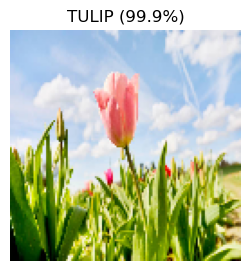

File : tulip2.jpg           | TULIP      | Accuracy : 100.00 %


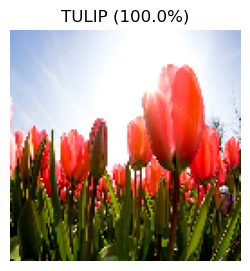

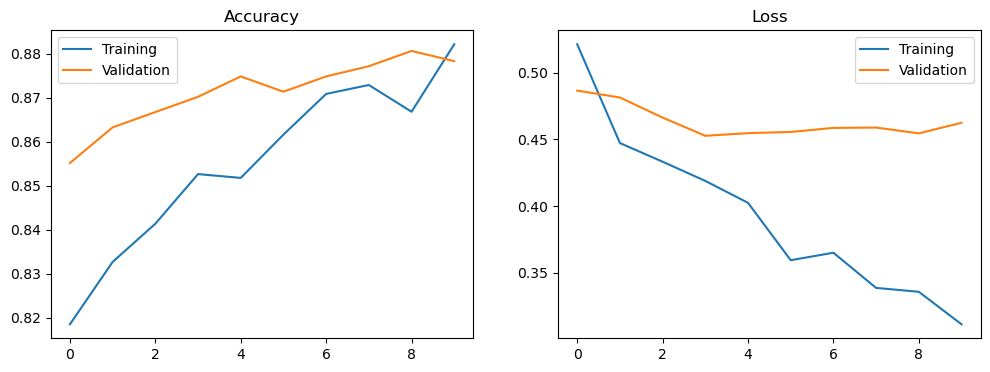

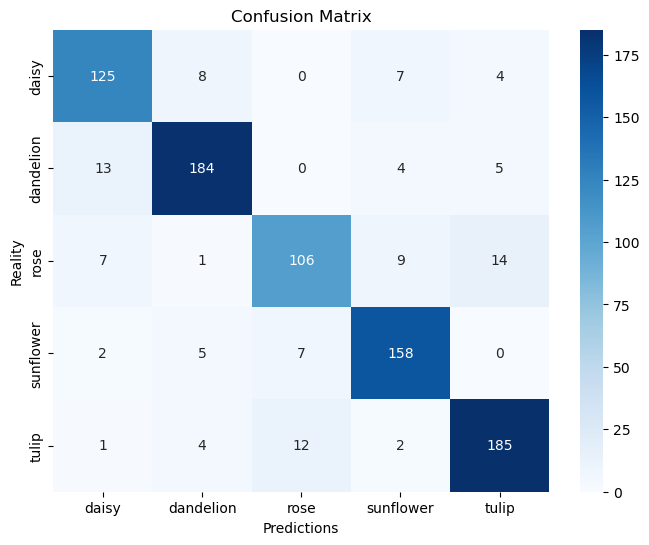

In [ ]:
FOLDER_TEST = "images"
MODEL_NAME = "models/my_flower_model.keras"
classes_name = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

#Load saved model
model = tf.keras.models.load_model(MODEL_NAME)

folder = os.listdir(FOLDER_TEST)
images_found = 0

for folder_name in folder:
    if folder_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        images_found += 1
        image_path = os.path.join(FOLDER_TEST, folder_name)

        #Load the image + resize them to 128,128
        image_raw = tf.keras.utils.load_img(image_path, target_size=(128, 128))
        image_tab = tf.keras.utils.img_to_array(image_raw)
        image_ready = np.expand_dims(image_tab, axis=0)

        predictions = model.predict(image_ready, verbose=0)

        winning_index = np.argmax(predictions[0])
        score = 100 * np.max(predictions[0])
        name_found = classes_name[winning_index].upper()

        display_name = folder_name[:18] + ".." if len(folder_name) > 20 else folder_name
        print(f"File : {display_name:<20} | {name_found:<10} | Accuracy : {score:>6.2f} %")

        plt.figure(figsize=(3, 3))
        plt.imshow(image_raw)
        plt.title(f"{name_found} ({score:.1f}%)")
        plt.axis('off')
        plt.show()

if images_found == 0:
    print("Images not found")

def curves(hist):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training')
    plt.plot(epochs_range, val_acc, label='Validation')
    plt.title('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training')
    plt.plot(epochs_range, val_loss, label='Validation')
    plt.title('Loss')
    plt.legend()
    plt.show()

curves(historique)
y_true = []
y_pred = []

for images, labels in dataset_validation:
    preds = modele.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=flowers_name, yticklabels=flowers_name, cmap='Blues')
plt.xlabel('Predictions')
plt.ylabel('Reality')
plt.title('Confusion Matrix')
plt.show()

model.save('optimize_flower_model.keras')